# Tracking Frequency, Phase, and Amplitude

In recent weeks, we have learned how to find the start of the signal and how to obtain initial estimates for amplitude, frequency, and phase errors. These initial estimates must be maintained throughout the reception of a signal frame. Of particular concern is a residual frequency error that leads to a build-up of phase error over time.

Today, we show how feedback control systems can be used to maintain accurate estimates - even if the true signal parameters are changing with time. The feedback control system for tracking the phase of the incoming signal is called a **phase-locked loop (PLL)**.

In [1]:
## Boilerplate instructions for importing NumPy and Matplotlib
# Import NumPy
import numpy as np

import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns
sns_context = "talk"
sns.set_theme(context=sns_context, style="ticks")

# proper labeling of plots
from matplotlib.ticker import EngFormatter

# some of the functions below have Type annotations
from typing import Tuple


## Phase-Locked Loops

A phase-locked loop aims to generate an estimate of the phase $\hat{\phi}[n]$ of the received signal $Z_n$; specifically, $Z_n$ is the output of the matched filter. It consists of three blocks

* The **phase detector** measures the phase difference between the incoming signal $Z_n$ and the phase estimate $\hat{\phi}[n]$. The phase detector can be further divided into 
    + a **phase rotator** that applies the phase correction $e^{-j\hat{\phi}[n]}$ to $Z_n$. The phase corrected signal $Z_n \cdot e^{-j\hat{\phi}[n]}$ is a suitable input to the decision rule.
    * The actual phase detection must strip any information symb $s_n$ from the output of the phase rotation, i.e., the phase detector computes the phase error $\Delta \phi$ as
    $$
    \Delta \phi[n] = \arg(\frac{Z_n \cdot e^{-j\hat{\phi}[n]}}{s_n}).
    $$
* The **loop filter** $H(z)$ scales and smoothes the phase errors $\Delta \phi[n]$.
* The **integrator** accumulates the filtered phase errors to produce the phase estimate $\hat{\phi}[n]$.

The loop will reach steady state when the phase errors $\Delta \phi[n]$ approach approach a constant; of course, we want that constant to be zero.

Since the PLL is stateful, i.e., it contains memory in its integrators, we will implement the PLL as a class; the state variable are stored as member variables.

### Loop Filters

We begin with classes for the first and second order loop filters that derive from a common base class that defines the basic interface and shared functionality for all loop filters.



In [2]:
class LoopFilter:
    def __init__(self):
        pass

    def __call__(self, error: float) -> float:
        raise NotImplementedError("This method should be implemented by subclasses.")

    def __repr__(self) -> str:
        return f"{self.__class__.__name__}()"

#### First-Order Filter

The first order filter returns a signal that is proportional to the input error. Mathematically, it can be expressed as:

$$
y[n] = \alpha \cdot d[n]
$$

where $$y[n]$$ is the output, $d[n]$ is the input error, and $\alpha$ is the proportional gain.

In [3]:
class First_Order_Filter(LoopFilter):
    """Class representing a first-order loop filter"""

    def __init__(self, alpha:float):
        """Initialize the gain of the filter
        
        Input:
        alpha - loop gain
        """
        super().__init__()
        self.alpha = alpha

    def __call__(self, d_n:float) -> float:
        """invoke the filter
        
        Input:
        d_n - single sample, representing error

        Returns:
        filtered sample; type is the same as the input
        """
        return self.alpha * d_n

    @property
    def alpha(self) -> float:
        return self._alpha

    @alpha.setter
    def alpha(self, new_val:float):
        if new_val < 2 and new_val > 0:
            self._alpha = new_val
        else:
            raise ValueError("alpha = {:} makes PLL unstable".format(new_val))

In [4]:
# The class is used like this
H1 = First_Order_Filter(0.1)  # instantiate filter
assert 0.2 == H1(2)           # pass d_n=2 to filter, output sould be 0.2 
assert 0.1 == H1.alpha        # retrieve the value of alpha
H1.alpha = 0.2               # change the gain 
assert 0.2 == H1.alpha       # and check it

#### Second Order Filter

The second-order loop filter adds an integrator to the first order filter.

In [5]:
class Second_Order_Filter(LoopFilter):
    """Class representing a second-order loop filter"""

    def __init__(self, alpha1:float, alpha2:float, state:float=0):
        """Initialize the gains and the state of the filter
        
        Input:
        alpha1 - linear gain
        alpha2 - integrator gain
        state - value held by integrator (optional, default: 0)
        """
        super().__init__()
        self.alpha1 = alpha1
        self.alpha2 = alpha2
        self.state = state

    def __call__(self, d_n:float) -> float:
        """invoke the filter
        
        Input:
        d_n - single sample, representing error

        Returns:
        filtered sample; type is the same as the input
        """
        out = self.alpha1 * d_n + self.state
        self.state += self.alpha2 * d_n  # update state
        
        return out

    # below, we check that 0 <= alpha2 < alpha1 < 1
    @property
    def alpha1(self):
        return self._alpha1

    @alpha1.setter
    def alpha1(self, new_val:float):
        if new_val < 1 and new_val > 0:
            self._alpha1 = new_val
        else:
            raise ValueError("alpha1 = {:} can make PLL unstable".format(new_val))

    @property
    def alpha2(self):
        return self._alpha2

    @alpha2.setter
    def alpha2(self, new_val:float):
        if new_val < self._alpha1 and new_val > 0:
            self._alpha2 = new_val
        else:
            raise ValueError("alpha2 = {:} can make PLL unstable".format(new_val))

    @property
    def state(self):
        return self._state

    @state.setter
    def state(self, new_val:float):
        self._state = new_val

    @property
    def damping_factor(self) -> float:
        return self.alpha1 / 2 / np.sqrt(self.alpha2) 

In [6]:
# The class is used like this
H2 = Second_Order_Filter(0.1, 0.025)  # instantiate filter
assert 0.2 == H2(2)                   # pass d_n=2 to filter, output sould be 0.2 
assert 0.05 == H2.state               # check that state was updated
assert 0.25 == H2(2)                  # pass 2 again, this time state is not zero
assert 0.1 == H2.alpha1               # retrieve the value of alpha1
H2.alpha1 = 0.2                       # change the gain 
assert 0.2 == H2.alpha1               # and check it
assert 0.025 == H2.alpha2             # retrieve the value of alpha2
H2.alpha2 = 0.01                      # change the gain 
assert 0.01 == H2.alpha2              # and check it
H2.state = 0                          # set the state
assert 0 == H2.state                  # and check it

print("Damping factor is {:f}".format(H2.damping_factor))

Damping factor is 1.000000


### Integrator

The final stateful element in the PLL is the integrator.

In [7]:
class Integrator():
    """Class representing an integrator"""

    def __init__(self, state:float=0):
        self.state = state

    def __call__(self, x_n:float) -> float:
        "Compute the output from the integrator"
        out = self.state
        self.state += x_n

        return out

    @property
    def state(self) -> float:
        return self._state

    @state.setter
    def state(self, new_val:float):
        self._state = new_val

In [8]:
# quick check that this works: a sequence of 1's integrates into a ramp
S = Integrator()
x = np.ones(10)
y = np.zeros_like(x)
for n in range(10):
    y[n] = S(x[n])

assert np.allclose(y, np.arange(10))


### Phase Rotation

Phase rotation is a stateless operation. Hence, a function suffices.

In [9]:
def rotate_phase(Z_n:complex, phi:float) -> complex:
    """Rotate the phase of the input signal backwards (i.e., by -phi)
    
    Inputs:
    Z_n - signal to be phase corrected
    phi - phase correction to apply

    Returns:
    complex sample
    """
    return Z_n * np.exp(-1j * phi)

### Phase Error

The final function measures the phase error between the received signal $Z_n$ and the phase estimate $\hat{\phi}[n]$; this is equivalent to measuring the residual phase error after applying the phase rotation.

However, before we can measure the phase error, any information symbols $s_n$ must be stripped off from the received signal $Z_n$.

In [10]:
def measure_phase(X_n:complex, s_n:complex=1) -> float:
    """measure the phase of modulated symbol 
    
    It is assumed that X_n = s_n * exp(j dphi) + N_n, where s_n is an information symbol
    and N_n is noise. The goal is to estimate the phase (error) dphi

    Inputs:
    X_n - sample of phase-rotated signal
    s_n - information symbol (default: 1)

    Returns:
    phase error estimate dphi
    """

    return np.angle(X_n / s_n)

### Putting it all together

We now have implementations of all components of the PLL. To test our implementation we will test it against a variety of signals with different phase errors.

We begin by setting parameters and allocating storage for results

In [11]:
## Parameters
# gains for a second order filter
alpha1 = 0.1
alpha2 = 0.004  # damping factor approximately 0.8

# noise level
SNR_db = 20
SNR = 10**(SNR_db/10)

# for simplicity, we start with a signal of all 1's, i.e., zero phase
N = 200
s = np.ones(N, dtype=complex)

# storage for intermediate results
dphi = np.zeros_like(s, dtype=np.float64)  # phase error
phi = np.zeros_like(s, dtype=np.float64)   # phase estimate
state_H = np.zeros_like(phi)               # state of loop filter
x = np.zeros_like(s)                       # phase rotated input
y = np.zeros_like(s, dtype=np.float64)     # filter output

#### Response to a constant phase error

The first phase error that we investigate is a step error: the phase of the input signal is $\pi/2$. The PLL is expected to learn this phase error and compensate it.

In [12]:
# define phase error - constant pi/2 for all samples
phase_error = np.pi/2 * np.ones(N)

# instantiate loop filter and integrator
H = Second_Order_Filter(alpha1, alpha2)
S = Integrator()

## make a received signal
# signal with phase error and noise
Z = s * np.exp(1j * phase_error) + 1/np.sqrt(2*SNR) * (np.random.randn(N) + 1j * np.random.randn(N))

# run the PLL; intermediate signals are stored for plotting/analysis
for n in range(N):
    phi[n] = S.state                   # correction to apply
    x[n] = rotate_phase(Z[n], phi[n])  # apply correction 
    dphi[n] = measure_phase(x[n], 1)   # measure residual phase error
    y[n] = H(dphi[n])                  # filter output
    
    # store the state of the loop filter if available, i.e., if this is a 2nd order filter
    try:
        state_H[n] = H.state
    except AttributeError:
        pass

    S(y[n])         # pass filter output to integrator, we get the output via S.state


**Note:** the operations of the tracking loop should be encapsulated in a `Tracker` class. We postpone that until a later time so that we can easily access the intermediate signals.

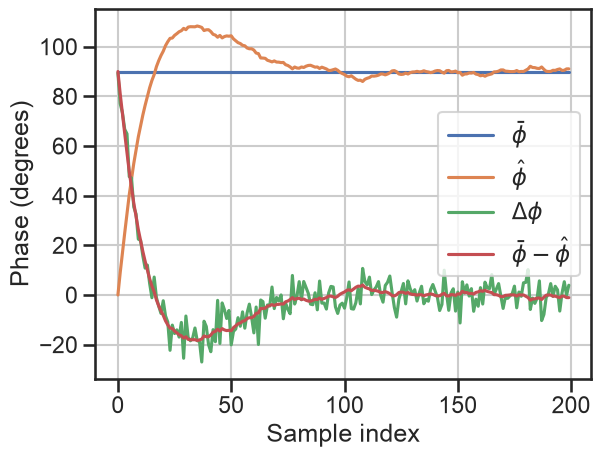

In [13]:
# plot phases
plt.plot(np.rad2deg(phase_error), label=r'$\bar{\phi}$')
plt.plot(np.rad2deg(phi), label=r'$\hat{\phi}$')
plt.plot(np.rad2deg(dphi), label=r'$\Delta \phi$')
plt.plot(np.rad2deg(np.pi/2 - phi), label=r'$\bar{\phi} - \hat{\phi}$')

plt.grid()
plt.legend()
plt.ylabel('Phase (degrees)')
plt.xlabel('Sample index')

plt.show()

The estimated phase $\hat{\phi}$ converges to the true phase $\pi/2$ (90 degrees).

Note also that the steady-state error $\bar{\phi} - \hat{\phi}$ is much smaller than the instantaneous phase error $\Delta \phi = \phi - \hat{\phi}$.

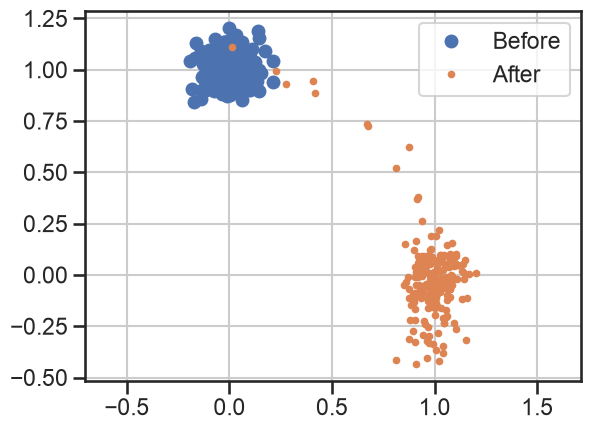

In [14]:
# Scatter plot of input before and after phase correction
plt.plot(Z.real, Z.imag, 'o', label='Before')
plt.plot(x.real, x.imag, '.', label='After')
plt.grid()
plt.axis('equal')
plt.legend()

plt.show()

After a few samples - and a little bit of overshoot - the PLL succeeds in rotating the "constellation" to the correct location centered on the real axis.

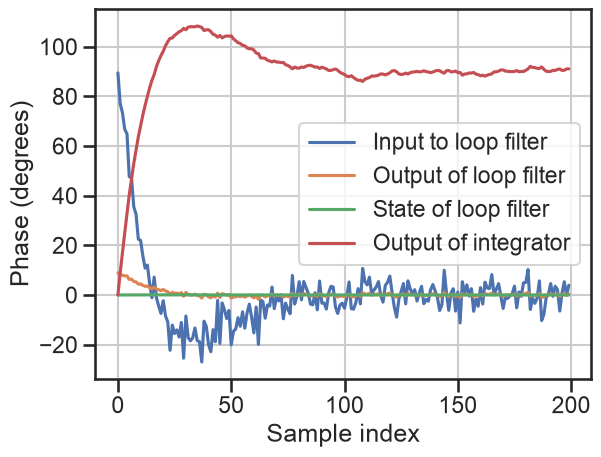

In [15]:
# plot internal signals
plt.plot(np.rad2deg(dphi), label="Input to loop filter")
plt.plot(np.rad2deg(y), label='Output of loop filter')
try:
    H.state
    plt.plot(state_H, label='State of loop filter')
except AttributeError:
    pass
plt.plot(np.rad2deg(phi), label='Output of integrator')

plt.ylabel('Phase (degrees)')
plt.xlabel('Sample index')
plt.grid()
plt.legend()
plt.show()

The output of the loop filter is a scaled and smoothed version of the input signal, i.e., the phase error $\Delta \phi$.

The state of the loop filter approaches zeros in steady state.

Recall that the output of the integrator (the phase estimate $\hat{\phi}$) is the obtained by integrating the output of the loop filter.

#### Response to a constant frequency error

The second phase error that we investigate is a ramp error: the phase of the input signal increases from $\pi/2$ to $\pi$ over the course of the observation. The (normalized) frequency offset is $\Delta f = \dfrac{1}{2\pi} \cdot \dfrac{\pi/2}{N} = \dfrac{1}{4N}$ per sample.

The second-order PLL is expected to learn this phase error and compensate it.

In [16]:
# define phase error - ramp from pi/2 to pi
phase_error = np.pi/2 * (1 + np.arange(N) / N)

# instantiate loop filter and integrator
H = Second_Order_Filter(alpha1, alpha2)
S = Integrator()

# make a received signal
Z = s * np.exp(1j * phase_error) + 1/np.sqrt(2*SNR) * (np.random.randn(N) + 1j * np.random.randn(N))

# run the PLL; intermediate signals are stored for analysis
for n in range(N):
    phi[n] = S.state
    x[n] = rotate_phase(Z[n], phi[n])
    dphi[n] = measure_phase(x[n], 1)
    y[n] = H(dphi[n])

    try:
        state_H[n] = H.state
    except AttributeError:
        pass
    
    S(y[n])

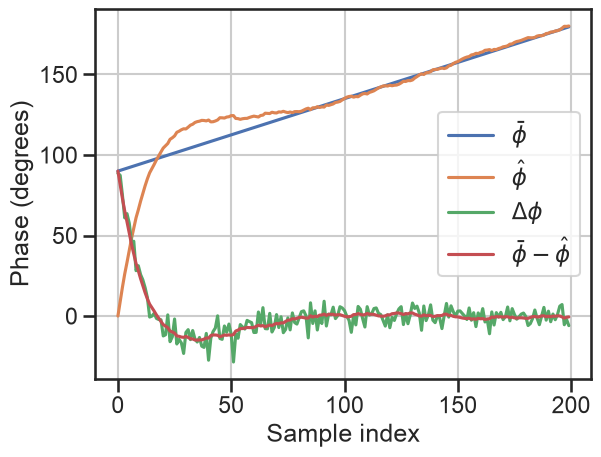

In [17]:
# plot phases
plt.plot(np.rad2deg(phase_error), label=r'$\bar{\phi}$')
plt.plot(np.rad2deg(phi), label=r'$\hat{\phi}$')
plt.plot(np.rad2deg(dphi), label=r'$\Delta \phi$')
plt.plot(np.rad2deg(np.pi/2 * (1 + np.arange(N) / N) - phi), label=r'$\bar{\phi} - \hat{\phi}$')

plt.ylabel('Phase (degrees)')
plt.xlabel('Sample index')
plt.grid()
plt.legend()

plt.show()

The estimated phase $\hat{\phi}$ rapidly converges to and tracks the phase of the input signal.

Again, the steady state error $\bar{\phi} - \hat{\phi}$ is much smaller than the instantaneous phase error $\Delta \phi = \phi - \hat{\phi}$.

Also, we see some overshoot as before.

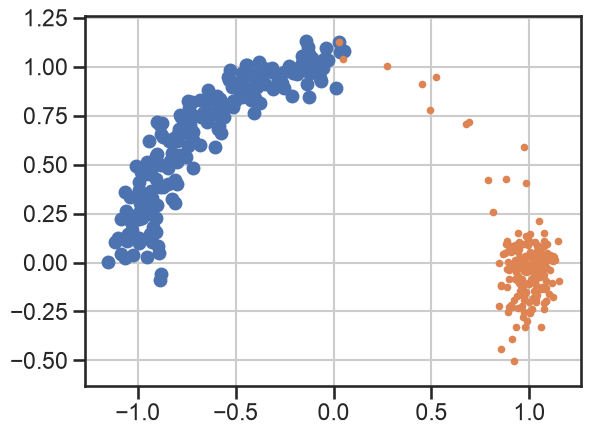

In [18]:
# Scatter plot of input before and after phase correcetion
plt.plot(Z.real, Z.imag, 'o', label='Before')
plt.plot(x.real, x.imag, '.', label='After')
plt.grid()
plt.axis('equal')

plt.show()

After a few samples, the rotated "constellation" is centered correctly on the real axis.

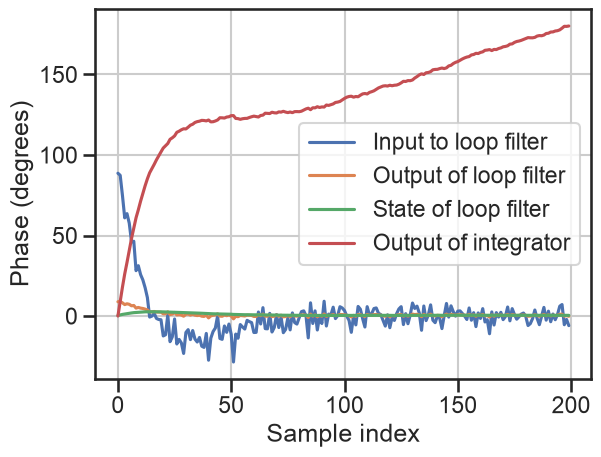

In [19]:
# plot internal signals
plt.plot(np.rad2deg(dphi), label="Input to loop filter")
plt.plot(np.rad2deg(y), label='Output of loop filter')
try:
    H.state
    plt.plot(np.rad2deg(state_H), label='State of loop filter')
except AttributeError:
    pass
plt.plot(np.rad2deg(phi), label='Output of integrator')

plt.ylabel('Phase (degrees)')
plt.xlabel('Sample index')
plt.grid()
plt.legend()
plt.show()

While the phase error (i.e., the input to the loop filter) approaches zero in state state, the output of the filter and the state of the filter do **not** approach zero. This is easier to see when the other signals are removed.

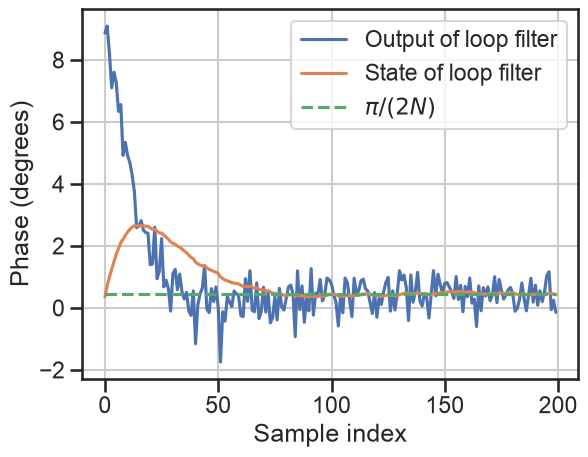

In [20]:
# close-up of loop-filter signals
plt.plot(np.rad2deg(y), label='Output of loop filter')
try:
    H.state
    plt.plot(np.rad2deg(state_H), label='State of loop filter')
except AttributeError:
    pass

plt.plot(np.arange(N), np.rad2deg(np.pi/2/N*np.ones(N)), '--', label=r'$\pi/(2N)$')

plt.ylabel('Phase (degrees)')
plt.xlabel('Sample index')
plt.grid()
plt.legend()
plt.show()

The output of the loop filter and the state of the loop filter do not converge to zero when there is a frequency offset.

In fact, the state of the second-order loop filter approaches $2\pi \Delta f$ (i.e,. $\pi/(2N)$ in this case). This is the phase increase between consecutive samples in the input signal.

#### Response to a time-varying frequency error

The final phase error that we investigate is a time-varying error: the phase of the input signal oscillates between $0$ and $\pi$ with a period equal to the length of the observation. The instantaneous normalized frequency of this signal varies between $\Delta f_{max} = \pi/(N)$ and $-\Delta f_{max} = -\pi/(N)$ over the course of the observation.

This is an extreme scenario that is unlikely to occur in practice. For example, if the symbol rate were 1MHz, then the frequency offset would change from 2.5KHz to -2.5KHz over a span of 100 $\mu s$. As such, this experiment is intended to serve as a stress test.

Still, the second-order PLL is expected to track this error fairly closely. However, it will not be able to eliminate it completely.

In [21]:
# define phase error - time-varying frequency error
phase_error = 2*np.pi/2 * (0 + np.sin(2*np.pi*np.arange(N)/N))

# instantiate loop filter and integrator
H = Second_Order_Filter(alpha1, alpha2)
S = Integrator()

# make a received signal
Z = s * np.exp(1j * phase_error) + 1/np.sqrt(2*SNR) * (np.random.randn(N) + 1j * np.random.randn(N))

# run the PLL; intermediate signals are stored for analysis
for n in range(N):
    phi[n] = S.state
    x[n] = rotate_phase(Z[n], phi[n])
    dphi[n] = measure_phase(x[n], 1)
    y[n] = H(dphi[n])
    try:
        state_H[n] = H.state
    except AttributeError:
        pass
    S(y[n])

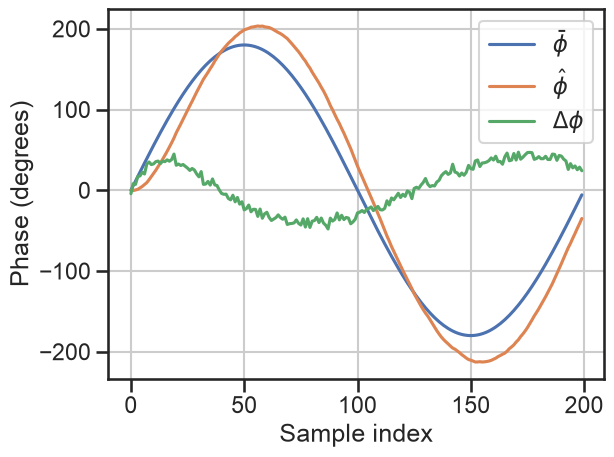

In [22]:
# plot phases
plt.plot(np.rad2deg(phase_error), label=r'$\bar{\phi}$')
plt.plot(np.rad2deg(phi), label=r'$\hat{\phi}$')
plt.plot(np.rad2deg(dphi), label=r'$\Delta \phi$')

plt.ylabel('Phase (degrees)')
plt.xlabel('Sample index')
plt.grid()
plt.legend()

plt.show()

The estimated phase follows the true phase, but it never quite catches up.

As a result, the phase error does not approach zero.

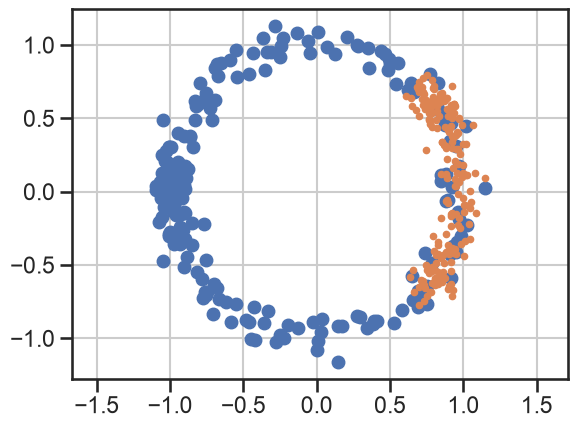

In [23]:
# Scatter plot of input before and after phase correction
plt.plot(Z.real, Z.imag, 'o', label='Before')
plt.plot(x.real, x.imag, '.', label='After')
plt.grid()
plt.axis('equal')

plt.show()

While the corrected "constellation" is closer to the correct solution on the real axis, there remains considerable phase error.

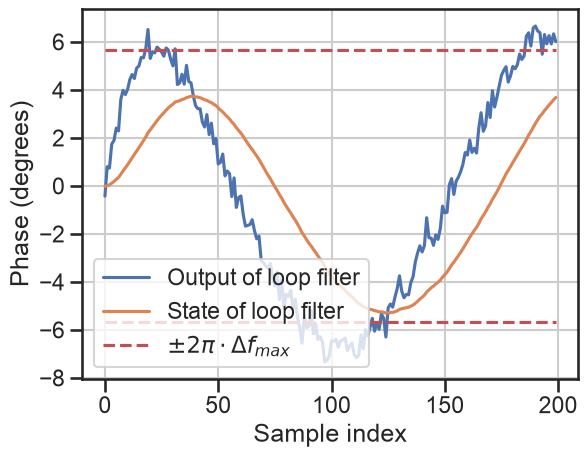

In [24]:
# close-up of loop-filter signals
plt.plot(np.rad2deg(y), label='Output of loop filter')
try:
    H.state
    plt.plot(np.rad2deg(state_H), label='State of loop filter')
except AttributeError:
    pass
plt.plot(np.arange(N), np.rad2deg(2*(np.pi)**2/N*np.ones(N)), 'r--', label=r'$\pm 2\pi \cdot \Delta f_{max}$')
plt.plot(np.arange(N), np.rad2deg(-2*(np.pi)**2/N*np.ones(N)), 'r--')

plt.ylabel('Phase (degrees)')
plt.xlabel('Sample index')
plt.grid()
plt.legend(loc='lower left')
plt.show()

The internal signals reflect the frequency variation. In particular, the state of the loop filter approaches the instantaneous frequency of the received signal.

## Amplitude Tracking

We have looked closely at tracking the phase of the received signal. In practice, we also need to maintain the amplitude of the received signal. This is critical for scaling the constellation correctly, especially for constellations that include multiple amplitudes (e.g., 16-QAM).

The tracking loop discussed above can be used for this purpose as long as we replace the phase detector with a device that measures the amplitude error. We need to make the following changes:

* The variable to be tracked by the loop is the inverse $\gamma$ of amplitude $A$ (i.e., $\gamma = 1/A$) instead of $\phi$. Our  estimate is denoted $\hat{\gamma}$.
* Instead of phase rotation, we need to scale the amplitude of the received signal. For that purpose, the received samples $Z_n$ are multiplied by $\hat{\gamma}$.
* To measure the amplitude error, we can use the metric $1-\frac{|Z_n|}{|s_n|}$, where $s_n$ is the information symbol during period $n$.

Thus, we need two additional functions for the amplitude tracking loop.

In [25]:
def scale_amplitude(Z_n: complex, gamma: float) -> complex:
    """Scale the amplitude of the input signal
    
    Inputs:
    Z_n - signal to be amplitude corrected
    gamma - amplitude correction to apply

    Returns:
    complex sample
    """
    return Z_n * gamma

In [26]:
def measure_amplitude_error(X_n: complex, s_n: complex = 1) -> float:
    """measure the amplitude error of modulated symbol 
    
    It is assumed that X_n = s_n * A + N_n, where s_n is an information symbol
    and N_n is noise. The goal is to estimate the gain gamma such that A * gamma = 1

    Inputs:
    X_n - sample of amplitude-scaled signal
    s_n - information symbol (default: 1)

    Returns:
    amplitude error estimate dA
    """

    return 1 - np.abs(X_n / s_n)

### Putting it together

We now have implementations of the components for the amplitude tracking loop. The loop filters and the integrator from the PLL can be re-used without change. 

The amplitude is not expected to change (much) over time. Hence, a first-order loop should suffice.

We begin by setting parameters and allocating storage for results

In [27]:
# Parameters
alpha = 0.1

SNR_db = 20
SNR = 10**(SNR_db/10)

# for simplicity, we start with a signal of all 1's, i.e., unit amplitude
N = 200
s = np.ones(N, dtype=complex)

# storage for intermediate results
dA = np.zeros_like(s, dtype=np.float64)    # amplitude error
gamma = np.zeros_like(s, dtype=np.float64) # estimate of 1/A
x = np.zeros_like(s)                       # amplitude scaled input
y = np.zeros_like(s, dtype=np.float64)     # filter output

In [28]:
# define amplitude error
amplitude_error = 1.5 * np.ones(N)

# instantiate loop filter and integrator
H = First_Order_Filter(alpha)
S = Integrator()

# make a received signal
Z = s * amplitude_error + 1/np.sqrt(2*SNR) * (np.random.randn(N) + 1j * np.random.randn(N))

# run the PLL; intermediate signals are stored for analysis
for n in range(N):
    gamma[n] = S.state
    x[n] = scale_amplitude(Z[n], gamma[n])
    dA[n] = measure_amplitude_error(x[n], 1)
    y[n] = H(dA[n])
    S(y[n])

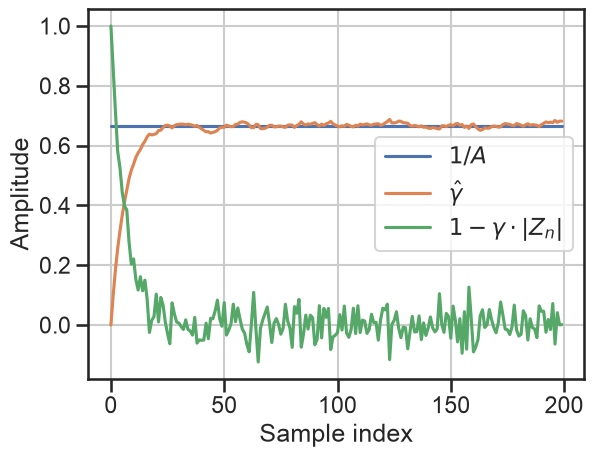

In [29]:
# plot amplitudes
plt.plot(1/amplitude_error, label=r'$1/A$')
plt.plot(gamma, label=r'$\hat{\gamma}$')
plt.plot(dA, label=r'$1 - \gamma \cdot |Z_n|$')

plt.ylabel('Amplitude')
plt.xlabel('Sample index')
plt.grid()
plt.legend()

plt.show()

## Tracking Phase and Amplitude

The two tracking loops work completely independently of each other. Hence, we can run the two loops either in parallel or in series.

For each sample, we will first perform phase correction and then amplitude correction:

1.  pass the matched filter outputs $Z_n$ to the PLL,
2. the pase correceted input $Z[n] \cdot e^{-j\phi[n]}$ is passed to the amplitude tracking loop,
3. the amplitude corrected input $\hat{\gamma} \cdot Z[n] \cdot e^{-j\phi[n]}$ is a suitable input to the decision rule.

Below is an illustration of the overall process.


In [30]:
# Parameters
alpha = 0.1     # gain for amplitude loop
alpha1 = 0.1    # gains for phase loop
alpha2 = 0.004

SNR_db = 20
SNR = 10**(SNR_db/10)

# for simplicity, we start with a signal of all 1's, i.e., unit amplitude
N = 200
s = np.ones(N, dtype=complex)

# storage for intermediate results
dphi = np.zeros_like(s, dtype=np.float64)    # phase error
phi = np.zeros_like(s, dtype=np.float64)     # phase estimate
dA = np.zeros_like(s, dtype=np.float64)      # amplitude error
gamma = np.zeros_like(s, dtype=np.float64)   # estimate of 1/A
x = np.zeros_like(s)                         # phase corrected input
y = np.zeros_like(s)                         # amplitude and phase corrected input

In [31]:
# define amplitude error
amplitude_error = 1.5 * np.ones(N)
phase_error = np.pi/2 * (1 + np.arange(N) / N)

# instantiate loop filters and integrators, one for each loop
HA = First_Order_Filter(alpha)
SA = Integrator()

HP = Second_Order_Filter(alpha1, alpha2)
SP = Integrator()

# make a received signal with both amplitude and phase error
Z = (s * amplitude_error * np.exp(1j * phase_error) + 
     amplitude_error/np.sqrt(2*SNR) * (np.random.randn(N) + 1j * np.random.randn(N))
)

# run the tracking loops
for n in range(N):
    # first the PLL
    phi[n] = SP.state
    x[n] = rotate_phase(Z[n], phi[n])        # this goes to amplitude loop
    dphi[n] = measure_phase(x[n], 1)
    tmp = HP(dphi[n])
    SP(tmp)

    # then the amplitude loop, input is the phase corrected input x[n]
    gamma[n] = SA.state
    y[n] = scale_amplitude(x[n], gamma[n])   # this is the input from above
    dA[n] = measure_amplitude_error(y[n], 1)  
    tmp = HA(dA[n])
    SA(tmp)


The two loops are executed sequentially; each sample $Z_n$ is first passed to the phase tracking loop. Then, the corrected phase is passed to amplitude tracking.

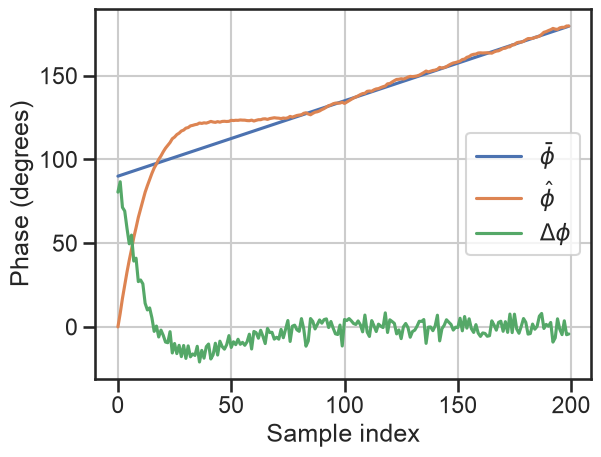

In [32]:
# plot phases
plt.plot(np.rad2deg(phase_error), label=r'$\bar{\phi}$')
plt.plot(np.rad2deg(phi), label=r'$\hat{\phi}$')
plt.plot(np.rad2deg(dphi), label=r'$\Delta \phi$')

plt.ylabel('Phase (degrees)')
plt.xlabel('Sample index')
plt.grid()
plt.legend()

plt.show()

The phase loop converges as before.

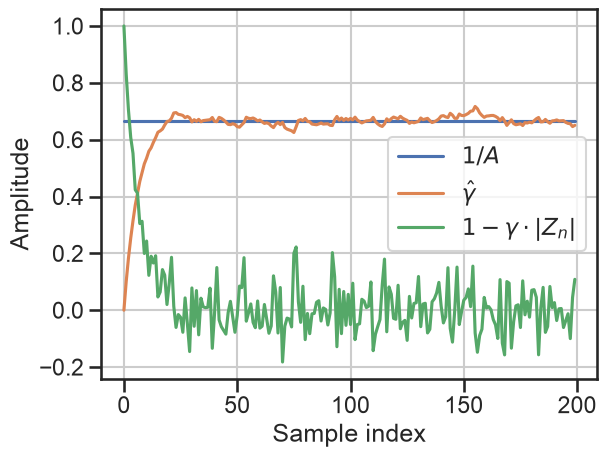

In [33]:
# plot amplitudes
plt.plot(1/amplitude_error, label=r'$1/A$')
plt.plot(gamma, label=r'$\hat{\gamma}$')
plt.plot(dA, label=r'$1 - \gamma \cdot |Z_n|$')

plt.ylabel('Amplitude')
plt.xlabel('Sample index')
plt.grid()
plt.legend()

plt.show()

And, the amplitude loop converges, too.

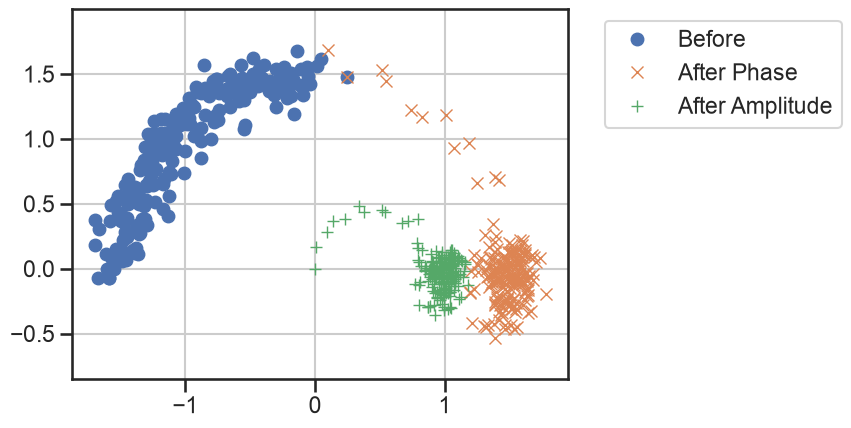

In [34]:
# Scatter plot of input before and after phase and amplitude corrections
plt.plot(Z.real, Z.imag, 'o', label='Before')
plt.plot(x.real, x.imag, 'x', label='After Phase')
plt.plot(y.real, y.imag, '+', label='After Amplitude')
plt.grid()
plt.axis('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

The corrections lead to the "constellation" being scaled and rotated correctly. The green symbols are centered correctly at $1+j0$ on the real axis.

## The complete acquisition and tracking process

Recently, we investigated the initial estimation of amplitude frequency and phase by means of the preamble signal.

Today, we illustrated how tracking loops can maintain good estimates of these parameters and perform fine corrections of the initial estimates.

We can combine the two processes by using the initial estimates to initialize the state of the tracking loops:

* the initial amplitude estimate $\hat{A}$ should be the initial state of the integrator in the frequency tracking loop.
* the initial frequency offset estimate $\hat{\Delta f}$ initializes the state of the second-order loop filter in the phase tracking loop.
* for the initial phase estimate we distinguish two cases; the initial phase estimate initializes the state of the integrator in the phase tracking loop:
    1. if the tracking loop starts with the first sample of the preamble, then the state of the integrator in the phase tracking loop is initialized to the phase estimate $\hat{\phi}$
    2. if tracking is to start with the first sample of the payload, then the state of that integrator must be initialized to $\hat{\phi} + 2\pi N_p \hat{\Delta f}$.

We illustrate the complete process below:

### Generate a signal

We use our tool box functions to synthesize a transmitted signal with preamble.

In [35]:
## imports from our toolbox
from dc_632_26.sources import RandomBitSource
from dc_632_26.pulses import SqrtRaisedCosinePulse
from dc_632_26.constellations import standard_constellation
from dc_632_26.modulation import modulation
from dc_632_26.pulse_shaper import PulseShaper
from dc_632_26.poly_phase_correlator import PolyPhaseCorrelator
from dc_632_26.estimator import Estimator
from dc_632_26.demodulation import GenericSlicer

In [36]:
## Signal parameters
# preamble - this is a length 31 M-sequence
preamble_bits = np.array([1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 
                          0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 
                          1, 1, 0, 1, 0], dtype=np.uint8)
K = len(preamble_bits)
preamble_constellation = standard_constellation.BPSK
preamble_symbols = modulation(preamble_bits, preamble_constellation)

# payload - 2000 random bits
N = 2000
payload_bits = RandomBitSource().get_bits(N)
payload_constellation = standard_constellation.QPSK
payload_symbols = modulation(payload_bits, payload_constellation)

# pulse shaping
fsT = 32
pulse = SqrtRaisedCosinePulse(num_samples=10*fsT, oversamp=fsT, alpha=0.5)
ps = PulseShaper(pulse, fsT)

sig = ps.generate_waveform(np.concatenate((preamble_symbols, payload_symbols)))


### Channel

The channel introduces a a phase and frequency offset and scales the amplitude.

AWGN is added to generate the received signal

In [37]:
## channel parameters
delay_samples = 102
ds_factor = 4       # down-sample by 4

df = 0.1/(fsT*(K-1))  # frequency offset per symbol period, phase change is 0.1*2*pi over course of preamble
X = 0.5*np.exp(1j*np.pi/4) # amplitude and phase

# delay by pre-pending zeros
rr = np.concatenate(( np.zeros(delay_samples), 
                     X * sig * np.exp(2j * np.pi * df * np.arange(len(sig))) ))

# down-sample
rr = rr[::ds_factor]
fsT_r = fsT // ds_factor

SNR_dB = 15
SNR = 10**(SNR_dB/10)
noise_var = abs(X)**2 / SNR 

# the down-sampled signal should have higher amplitude  
rr = np.sqrt(ds_factor)*rr + np.sqrt(0.5 * noise_var) * (np.random.randn(len(rr)) + 1j*np.random.randn(len(rr))) 

### Receiver Processing

Processing in the receiver begins with the steps that we discussed previously. We are not using the `Receiver` class directly so that we have access to the various signals in the processing chain. The tracking loops will be integrated into the `Receiver` at a later time. The processing steps include:
* matched filtering,
* computing correlations for the different sampling phases
* locating the preamble, including the best sampling phase,
* followed by initial parameter estimates derived from the preamble.


In [38]:
## matched filter output
# we need a different pulse than the transmitter because the oversampling factor is different
mf_hh = SqrtRaisedCosinePulse(num_samples=10*fsT_r, oversamp=fsT_r, alpha=0.5)._generate_samples()
mf_out = np.convolve(rr, np.flipud(mf_hh.conj()))

# prepare for the polyphase correlation loop
num_phases = fsT_r
num_symbols = len(mf_out) // num_phases
corrs = np.zeros((num_phases, num_symbols), dtype=complex)
mags = np.zeros((num_phases, num_symbols), dtype=float)

# instantiate the polyphase correlator
pp_corr = PolyPhaseCorrelator(preamble_symbols, num_phases=num_phases)

for k in range(num_symbols):
    for p in range(num_phases):
        sample = mf_out[k*num_phases + p]
        corr, mag = pp_corr.update(sample)
        corrs[p, k] = corr
        mags[p, k] = mag

# locate peak correlation
m_ind = np.argmax(np.abs(corrs), axis=1)
p_ind = np.argmax([np.abs(corrs[i, m_ind[i]]) for i in range(num_phases)])
k_ind = m_ind[p_ind]

print(f"Peak correlation at phase index {p_ind}, symbol index {k_ind}")
print(f"Preamble extends from symbol index {k_ind-len(preamble_symbols) + 1} to {k_ind}")

Peak correlation at phase index 1, symbol index 43
Preamble extends from symbol index 13 to 43


We can now isolate the preamble and the payloads based on the peak correlation location. 

The received preamble symbols are used to compute initial estimates for amplitude, phase, and frequency.

In [39]:
mf_out_pind = mf_out[p_ind::fsT_r]
preamble_symbols_received = mf_out_pind[k_ind-len(preamble_symbols) + 1:k_ind+1]
payload_symbols_received = mf_out_pind[k_ind+1:k_ind+1+N]

estimator = Estimator(preamble_symbols, 2)

freq_offset, complex_gain, noise_var_est = estimator.estimate(preamble_symbols_received)

print(f"Estimated frequency offset: {freq_offset:.6f} per symbol (true value: {df*fsT:.6f})")
print(f"Estimated gain: {np.abs(complex_gain):.6f} (true value: {0.5})")
print(f"Estimated phase: {np.angle(complex_gain)/np.pi:.6f}*pi (true value: {0.25}*pi)")
print(f"Estimated noise variance: {noise_var_est:.6f} (true value: {noise_var:.6f})")


Estimated frequency offset: 0.003077 per symbol (true value: 0.003333)
Estimated gain: 0.506104 (true value: 0.5)
Estimated phase: 0.295892*pi (true value: 0.25*pi)
Estimated noise variance: 0.014040 (true value: 0.007906)


We obtained "decent" initial estimate for the unknown channel parameters. These estimates will be used to initialize the tracking loops for frequency offset, phase, and gain.

Note: the estimate of the noise variance isn't very accurate!?

### Using Initial estimates for demodulation

If the initial estimates of amplitude, phase, and frequency are reasonably accurate, we should be able to demodulate the received signal. Let's see how well this works.

Keep in mind that the estimated phase is at the start of the preamble. Over the course of the preamble the phase changes due to the frequency offset. This change must be reflected.

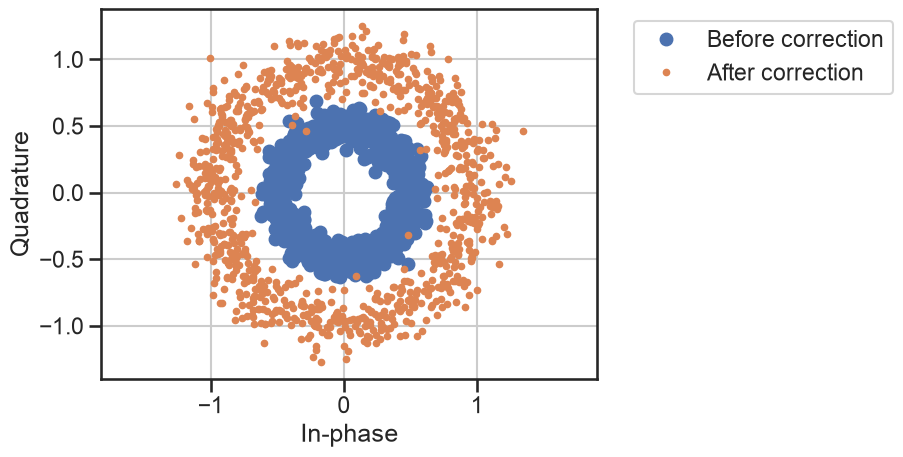

In [40]:
# amplitude correction
Ns = len(payload_symbols)
payload_symbols_corrected = payload_symbols_received[:Ns] * 1/np.abs(complex_gain)

# phase and frequency correction
phase_ppayload = np.angle(complex_gain) + 2*np.pi*freq_offset*len(preamble_symbols)
payload_symbols_corrected *= np.exp(-1j*(2*np.pi*freq_offset*np.arange(len(payload_symbols_corrected)) + phase_ppayload))

# Scatter plot of input before and after phase and amplitude corrections
plt.plot(payload_symbols_received[:Ns].real, payload_symbols_received[:Ns].imag, 'o', label='Before correction')
plt.plot(payload_symbols_corrected.real, payload_symbols_corrected.imag, '.', label='After correction')
plt.grid()
plt.axis('equal')
plt.xlabel('In-phase')
plt.ylabel('Quadrature')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

The residual frequency offset does not completely stop the constellation from spinning! We will still get a large number of errors, especially for long frames.

### Tracking loops

We choose to start our tracking loops with the preamble. For that purpose, we
* initialize the states of the integrators in the loop
* then run the loops using the known training symbols

#### Initialize the tracking loops using the preamble

In [41]:
# pull out preamble samples and allocate storage for intermediate results
Z_hat = preamble_symbols_received                # <- this is the input signal to the loop
dphi = np.zeros_like(Z_hat, dtype=float)    # phase error
phi = np.zeros_like(Z_hat, dtype=float)     # phase estimate
dA = np.zeros_like(Z_hat, dtype=float)      # amplitude error
gamma = np.zeros_like(Z_hat, dtype=float)   # estimate of 1/A
x = np.zeros_like(Z_hat)                         # phase corrected input
y = np.zeros_like(Z_hat)                         # amplitude and phase corrected input

In [42]:
# instantiate loop filters and integrators, one for each loop
HA = First_Order_Filter(alpha)
SA = Integrator()
SA.state = 1/np.abs(complex_gain)  # initialize amplitude loop with 1/amplitude estimate

HP = Second_Order_Filter(alpha1, alpha2)
SP = Integrator()
SP.state = np.angle(complex_gain)  # initialize phase loop with phase estimate
HP.state = 2*np.pi*freq_offset     # and frequency estimate

## now run the tracking loop over the preamble symbols (length K)
for n in range(K):
    # first the PLL
    phi[n] = SP.state
    x[n] = rotate_phase(Z_hat[n], phi[n])        # this goes to amplitude loop
    dphi[n] = measure_phase(x[n], preamble_symbols[n])
    tmp = HP(dphi[n])
    SP(tmp)

    # then the amplitude loop, input is the phase corrected input x[n]
    gamma[n] = SA.state
    y[n] = scale_amplitude(x[n], gamma[n])   # x[n] is the input from above
    dA[n] = measure_amplitude_error(y[n], preamble_symbols[n])  
    tmp = HA(dA[n])
    SA(tmp)
    

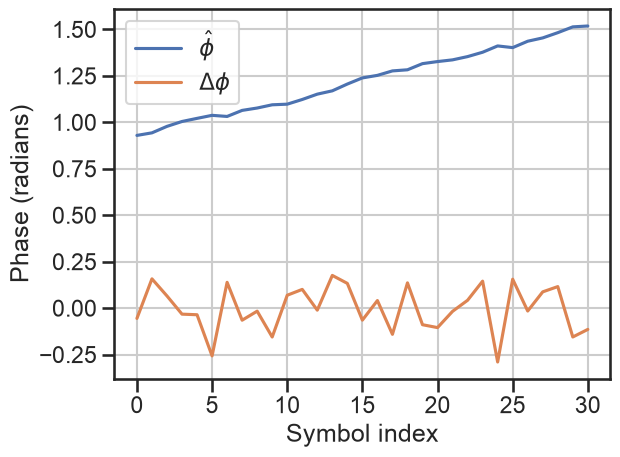

In [43]:
# plot tracked phase
plt.plot(phi, label=r'$\hat{\phi}$')
plt.plot(dphi, label=r'$\Delta \phi$')

plt.xlabel('Symbol index')
plt.ylabel('Phase (radians)')
plt.grid()
plt.legend()

plt.show()

By using the initial estimates for phase and frequency, the phase errors are near zero from the beginning; the transient is avoided.

The frequency estimate should also have improved; we can retrieve the estimate implicit in the tracker from the tracking loop.

In [44]:
print(f"Implied frequency estimate at end of premable: {HP.state/(2*np.pi):.6f} (true value {df*fsT:.6f})")

Implied frequency estimate at end of premable: 0.003041 (true value 0.003333)


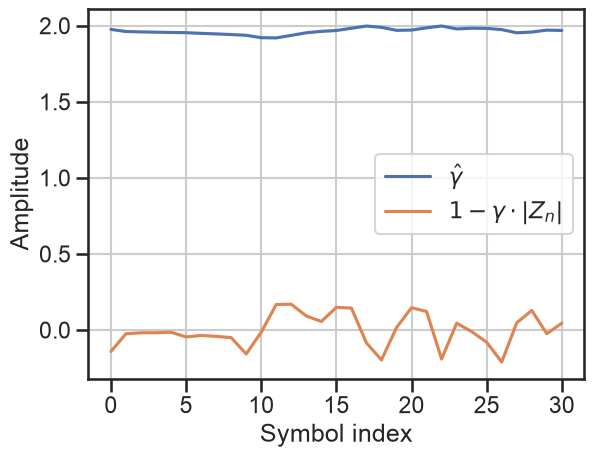

In [45]:
# plot amplitudes
plt.plot(gamma, label=r'$\hat{\gamma}$')
plt.plot(dA, label=r'$1 - \gamma \cdot |Z_n|$')

plt.xlabel('Symbol index')
plt.ylabel('Amplitude')
plt.grid()
plt.legend()

plt.show()

The same observation applies to the amplitude tracking loop.

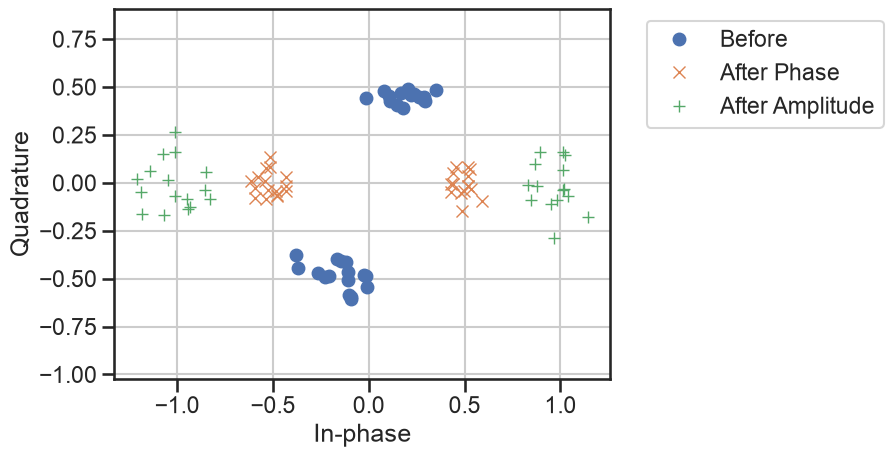

In [46]:
# Scatter plot of input before and after phase and amplitude corrections
plt.plot(Z_hat.real, Z_hat.imag, 'o', label='Before')
plt.plot(x.real, x.imag, 'x', label='After Phase')
plt.plot(y.real, y.imag, '+', label='After Amplitude')
plt.grid()
plt.axis('equal')
plt.xlabel('In-phase')
plt.ylabel('Quadrature')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

#### Using the tracking loop to demodulate symbols

Now that the tracking loops are "warmed up" we can use them during the symbol modulation phase. Again, we have two options.

1. We can turn off (set to zero) any further inputs to the loops; this is equivalent to applying corrections according to the most recent estimates reflected in the state variables of the loops.
2. We can continue to update the state of the loop. In place of the training symbols $p[n]$, we would need to use *symbol decisions* during phase and amplitude measurements.

The second approach is illustrated below.

In [47]:
# pull out information bearing samples and allocate storage for intermediate results
Z_hat = payload_symbols_received                 # <- this is the input signal to the loop
dphi = np.zeros_like(Z_hat, dtype=float)    # phase error
phi = np.zeros_like(Z_hat, dtype=float)     # phase estimate
dA = np.zeros_like(Z_hat, dtype=float)      # amplitude error
gamma = np.zeros_like(Z_hat, dtype=float)   # estimate of 1/A
x = np.zeros_like(Z_hat)                         # phase corrected input
y = np.zeros_like(Z_hat)                         # amplitude and phase corrected input
dec = np.zeros_like(Z_hat)                       # symbol decisions

In [48]:
## DO NOT modify the state of the tracking loops!!
slicer = GenericSlicer(payload_constellation)

## run the tracking loop over the information symbols (length Ns)
Ns = N // payload_constellation.bits_per_symbol
for n in range(Ns):
    # perform phase and amplitude corrections
    phi[n] = SP.state
    x[n] = rotate_phase(Z_hat[n], phi[n])        # this goes to amplitude loop
    gamma[n] = SA.state
    y[n] = scale_amplitude(x[n], gamma[n])       # this goes to the decision rule

    # slicer returns bits, but we need symbols (grrr)
    bits = slicer.slice_symbols(np.array([y[n]]))
    dec[n] = modulation(bits, payload_constellation)[0]

    dphi[n] = measure_phase(x[n], dec[n])       # decision feedback
    tmp = HP(dphi[n])
    SP(tmp)

    # then the amplitude loop, input is the phase corrected input x[n]
    dA[n] = measure_amplitude_error(y[n], dec[n]) # decision feedback 
    tmp = HA(dA[n])
    SA(tmp)

# count bit errors
rx_bits = slicer.slice_symbols(y[:Ns])
n_bit_errors = np.sum(np.not_equal(rx_bits, payload_bits))
print(f"Found {n_bit_errors:d} errors")
    

Found 0 errors


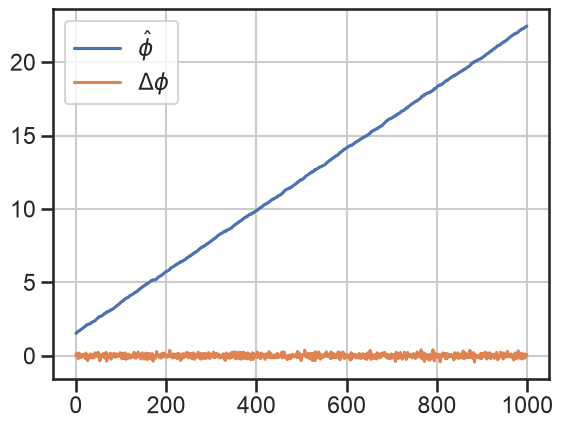

In [49]:
# plot phases
plt.plot(phi[:Ns], label=r'$\hat{\phi}$')
plt.plot(dphi[:Ns], label=r'$\Delta \phi$')

plt.grid()
plt.legend()

plt.show()

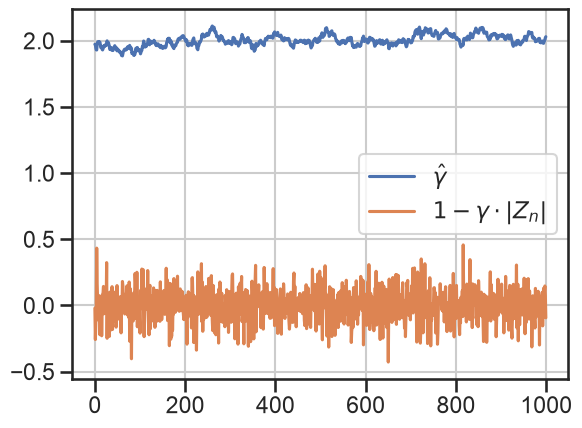

In [50]:
# plot amplitudes
plt.plot(gamma[:Ns], label=r'$\hat{\gamma}$')
plt.plot(dA[:Ns], label=r'$1 - \gamma \cdot |Z_n|$')

plt.grid()
plt.legend()

plt.show()

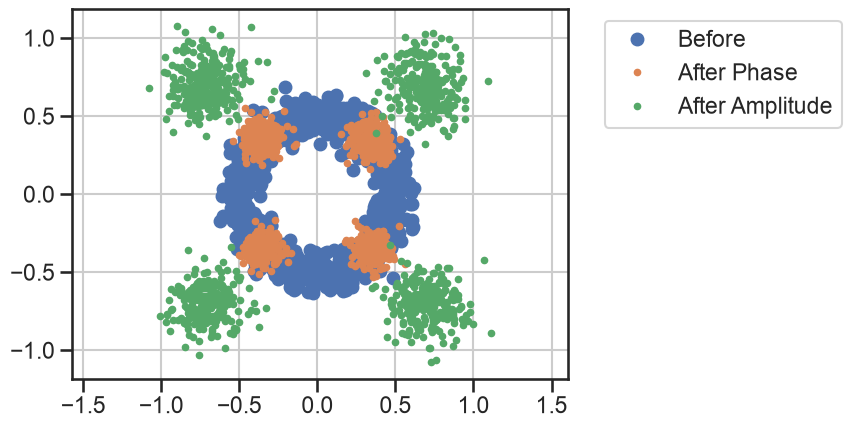

In [51]:
# Scatter plot of input before and after phase and amplitude correcetions
plt.plot(Z_hat[:Ns].real, Z_hat[:Ns].imag, 'o', label='Before')
plt.plot(x[:Ns].real, x[:Ns].imag, '.', label='After Phase')
plt.plot(y[:Ns].real, y[:Ns].imag, '.', label='After Amplitude')
plt.grid()
plt.axis('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## Summary

We have illustrated how tracking loops can be used to maintain accurate estimates of amplitude, frequency, and phase - even if these parameters vary over time.

In combination with the initial estimates obtained from the preamble, the tracking loops provide the accurate parameters needed to successfully demodulate symbols in the face of unknown and/or time-varying channel parameters.

### Loose Ends

The tracking loops accurate amplitude, phase, and frequency estimates that are used to correct channel effects. However, there is a number of loose ends that need to be tied up:

* the tracking loops should be packaged into a reusable class
* the tracking loops need to be integrated into the `Receiver` class
* the slicer should be revisited to allow symbol estimates as outputs (instead of just bits)
* the estimate of the noise variance isn't very good - why is that?
* the demodulation process above assumed that the number of symbols is known; that isn't realistic.

And then there is the problem that the channel may introduce more complex distortion than just amplitude, phase, and frequency offsets...